# Notebook 07 - Evaluasi Final DDS vs noDDS

**Tahap penelitian:** Evaluasi -> Selesai.

Notebook ini mengukur kinerja test dari tiga algoritma pada dua varian dataset: DDS (174 fitur) dan noDDS (164 fitur). Keenam model memakai konfigurasi baseline yang ditetapkan di Notebook 04 dan dievaluasi pada board test yang sama. Hasil test hanya dipakai untuk pelaporan perbandingan, bukan untuk memilih algoritma atau mengubah threshold.


## 0. Setup


In [1]:
import sys
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

_root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _root_candidates if (p / 'configs' / 'config.yaml').exists() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Tidak menemukan root repo. Jalankan notebook dari root repo atau folder notebooks.')
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs' / 'results'
MODEL_DIR = ROOT / 'outputs' / 'models'
OUT.mkdir(parents=True, exist_ok=True)

from src.preprocessing import load_splits
from src.evaluation import evaluate, print_summary, save_results

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})
sns.set_theme(style='whitegrid', palette='colorblind')
print(f'Repo: {ROOT}')


Repo: D:\Bridge-Prediction


## 1. Muat pasangan dataset dan evaluasi enam model


In [2]:
from src.preprocessing import load_splits
from src.evaluation import evaluate, print_summary, save_results

DATASET_DIRS = {'DDS': ROOT / 'data' / 'processed', 'noDDS': ROOT / 'data' / 'processed_no_dds'}
ALGORITHMS = ('RandomForest', 'XGBoost', 'LightGBM')
splits_by_dataset = {}
feature_cols_by_dataset = {}
label_encoders = {}
for variant, data_dir in DATASET_DIRS.items():
    train_df, val_df, test_df, features, label_encoder = load_splits(data_dir)
    splits_by_dataset[variant] = {'train': train_df, 'val': val_df, 'test': test_df}
    feature_cols_by_dataset[variant] = features
    label_encoders[variant] = label_encoder
    assert len(features) == (174 if variant == 'DDS' else 164)

identity_cols = ['_source_file', '_room', '_board_number', '_deal_key', 'label', 'matches_par_contract']
for variant_part in ('train', 'val', 'test'):
    assert splits_by_dataset['DDS'][variant_part][identity_cols].equals(
        splits_by_dataset['noDDS'][variant_part][identity_cols]
    ), f'Split atau label DDS/noDDS berbeda pada {variant_part}'

y_test = splits_by_dataset['noDDS']['test']['label'].to_numpy()
label_encoder = label_encoders['noDDS']
assert np.array_equal(y_test, splits_by_dataset['DDS']['test']['label'].to_numpy())

model_files = {
    'DDS': {name: MODEL_DIR / f'{name.lower()}_dds.pkl' for name in ALGORITHMS},
    'noDDS': {name: MODEL_DIR / f'{name.lower()}.pkl' for name in ALGORITHMS},
}
final_results = []
predictions = {}
probabilities = {}
for variant in ('DDS', 'noDDS'):
    test_df = splits_by_dataset[variant]['test']
    features = feature_cols_by_dataset[variant]
    X_test = test_df[features].to_numpy(dtype=np.float32)
    for algorithm in ALGORITHMS:
        model_path = model_files[variant][algorithm]
        if not model_path.exists():
            raise FileNotFoundError(f'Model tidak ditemukan: {model_path}. Jalankan Notebook 04.')
        model = joblib.load(model_path)
        name = f'{algorithm} ({variant})'
        proba = model.predict_proba(X_test)
        pred = model.predict(X_test)
        result = evaluate(y_test, pred, proba, label_encoder, model_name=name)
        result['algorithm'] = algorithm
        result['dataset_variant'] = variant
        final_results.append(result)
        predictions[name] = pred
        probabilities[name] = proba
        save_results(result, OUT / f"nb07_{algorithm.lower()}_{variant.lower()}_test.json")
        print_summary(result)

print(f"Semua enam model diuji pada {len(y_test):,} board test; prevalensi positif {y_test.mean():.2%}.")



  RandomForest (DDS)
  Accuracy          : 0.8032
  Precision (macro) : 0.7367
  Recall (macro)    : 0.6939
  F1 (macro)        : 0.7095
  F1 (weighted)     : 0.7935
  F1 (positive)     : 0.5446
  ROC-AUC           : 0.7812
  PR-AUC (avg prec) : 0.5888

  XGBoost (DDS)
  Accuracy          : 0.8089
  Precision (macro) : 0.7596
  Recall (macro)    : 0.6716
  F1 (macro)        : 0.6947
  F1 (weighted)     : 0.7898
  F1 (positive)     : 0.5080
  ROC-AUC           : 0.7921
  PR-AUC (avg prec) : 0.5946



  LightGBM (DDS)
  Accuracy          : 0.7916
  Precision (macro) : 0.7220
  Recall (macro)    : 0.7393
  F1 (macro)        : 0.7295
  F1 (weighted)     : 0.7954
  F1 (positive)     : 0.5999
  ROC-AUC           : 0.8153
  PR-AUC (avg prec) : 0.6285



  RandomForest (noDDS)
  Accuracy          : 0.7500
  Precision (macro) : 0.6391
  Recall (macro)    : 0.5915
  F1 (macro)        : 0.5999
  F1 (weighted)     : 0.7247
  F1 (positive)     : 0.3549
  ROC-AUC           : 0.7051
  PR-AUC (avg prec) : 0.4356

  XGBoost (noDDS)
  Accuracy          : 0.7600
  Precision (macro) : 0.6582
  Recall (macro)    : 0.5532
  F1 (macro)        : 0.5445
  F1 (weighted)     : 0.7040
  F1 (positive)     : 0.2313
  ROC-AUC           : 0.7086
  PR-AUC (avg prec) : 0.4386



  LightGBM (noDDS)
  Accuracy          : 0.7140
  Precision (macro) : 0.6312
  Recall (macro)    : 0.6468
  F1 (macro)        : 0.6367
  F1 (weighted)     : 0.7220
  F1 (positive)     : 0.4692
  ROC-AUC           : 0.7046
  PR-AUC (avg prec) : 0.4180
Semua enam model diuji pada 7,532 board test; prevalensi positif 24.55%.


## 2. Perbandingan metrik test


In [3]:
metric_names = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc', 'average_precision',
                'precision_positive', 'recall_positive', 'f1_positive']
metrics_df = pd.DataFrame([
    {'Model': r['model'], **{m: r[m] for m in metric_names if m in r}}
    for r in final_results
]).set_index('Model')
metrics_df.to_csv(OUT / 'nb07_dds_vs_nodds_test_comparison.csv')
display(metrics_df.style.format('{:.4f}').highlight_max(color='#C8E6C9', axis=0))

paired_deltas = []
for algorithm in ALGORITHMS:
    dds = next(r for r in final_results if r['algorithm'] == algorithm and r['dataset_variant'] == 'DDS')
    nodds = next(r for r in final_results if r['algorithm'] == algorithm and r['dataset_variant'] == 'noDDS')
    paired_deltas.append({
        'Algoritma': algorithm,
        **{f'DDS - noDDS ({m})': float(dds[m] - nodds[m]) for m in metric_names if m in dds and m in nodds},
    })
delta_df = pd.DataFrame(paired_deltas).set_index('Algoritma')
delta_df.to_csv(OUT / 'nb07_dds_feature_metric_delta.csv')
print('Selisih positif berarti metrik meningkat saat 10 fitur trik DDS disertakan.')
display(delta_df.style.format('{:+.4f}'))


,accuracy,f1_macro,f1_weighted,roc_auc,average_precision,precision_positive,recall_positive,f1_positive
Model,,,,,,,,
RandomForest (DDS),0.8032,0.7095,0.7935,0.7812,0.5888,0.6306,0.4792,0.5446
XGBoost (DDS),0.8089,0.6947,0.7898,0.7921,0.5946,0.6905,0.4018,0.5080
LightGBM (DDS),0.7916,0.7295,0.7954,0.8153,0.6285,0.5672,0.6366,0.5999
RandomForest (noDDS),0.7500,0.5999,0.7247,0.7051,0.4356,0.4841,0.2802,0.3549
XGBoost (noDDS),0.7600,0.5445,0.7040,0.7086,0.4386,0.5408,0.1471,0.2313
LightGBM (noDDS),0.7140,0.6367,0.7220,0.7046,0.4180,0.4310,0.5149,0.4692


Selisih positif berarti metrik meningkat saat 10 fitur trik DDS disertakan.


,DDS - noDDS (accuracy),DDS - noDDS (f1_macro),DDS - noDDS (f1_weighted),DDS - noDDS (roc_auc),DDS - noDDS (average_precision),DDS - noDDS (precision_positive),DDS - noDDS (recall_positive),DDS - noDDS (f1_positive)
Algoritma,,,,,,,,
RandomForest,+0.0532,+0.1096,+0.0689,+0.0762,+0.1532,+0.1465,+0.1990,+0.1896
XGBoost,+0.0490,+0.1502,+0.0858,+0.0835,+0.1560,+0.1498,+0.2547,+0.2767
LightGBM,+0.0775,+0.0927,+0.0734,+0.1107,+0.2105,+0.1363,+0.1217,+0.1307


## 3. Confusion matrix


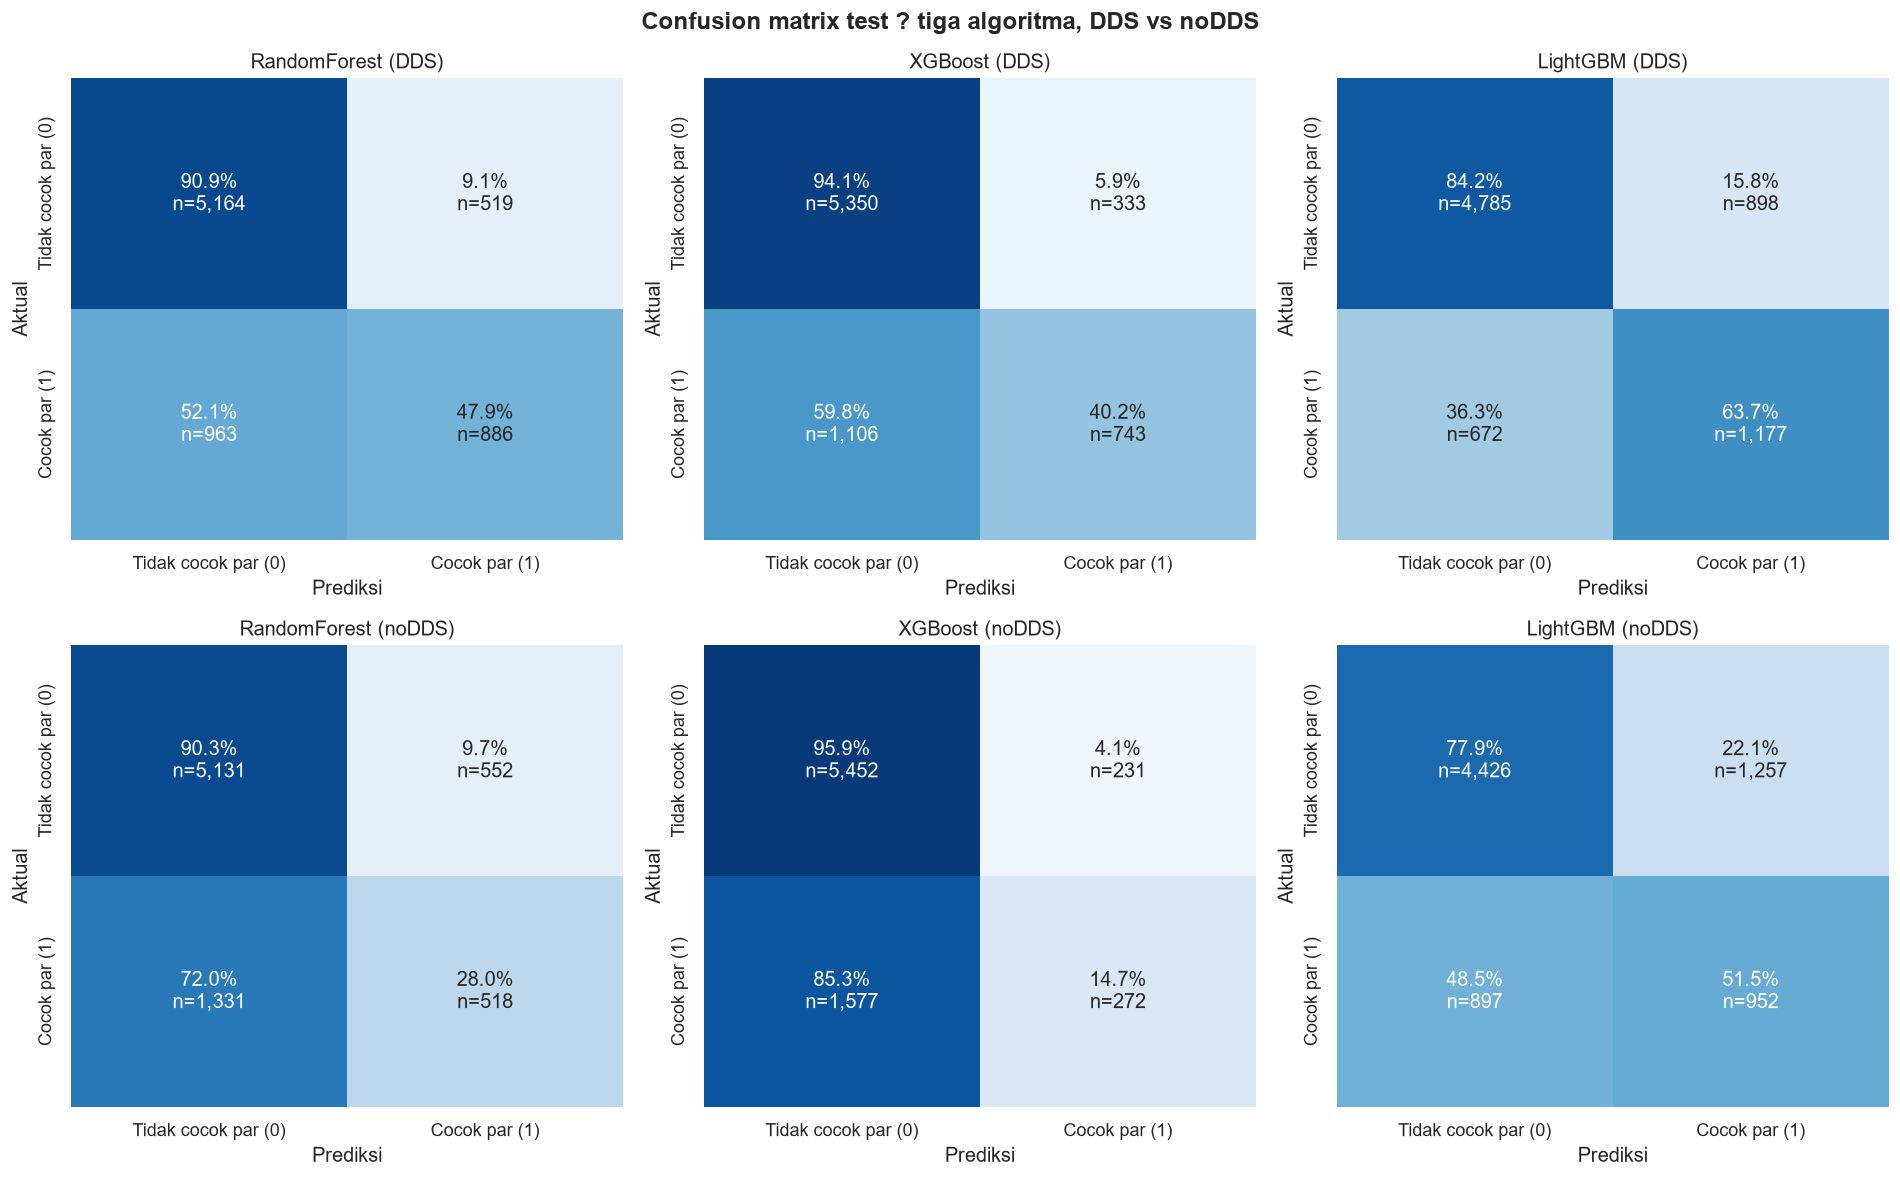

In [4]:
from sklearn.metrics import confusion_matrix

class_names = ['Tidak cocok par (0)', 'Cocok par (1)']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, result in zip(axes.flat, final_results):
    name = result['model']
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    totals = matrix.sum(axis=1, keepdims=True)
    matrix_pct = np.divide(matrix * 100.0, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    labels = np.array([[f'{matrix_pct[r,c]:.1f}%\nn={matrix[r,c]:,}' for c in range(2)] for r in range(2)])
    sns.heatmap(matrix_pct, annot=labels, fmt='', cmap='Blues', vmin=0, vmax=100,
                xticklabels=class_names, yticklabels=class_names, cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
fig.suptitle('Confusion matrix test ? tiga algoritma, DDS vs noDDS', fontweight='bold')
fig.tight_layout()
plt.savefig(OUT / 'nb07_dds_vs_nodds_confusion_matrices.png', bbox_inches='tight', dpi=160)
plt.show()


## 4. Ringkasan dan Kesimpulan


In [5]:
summary = {
    'comparison': 'paired DDS (174 fitur) vs noDDS (164 fitur)',
    'target': 'matches_par_contract',
    'test_rows': int(len(y_test)),
    'test_positive_rate': float(y_test.mean()),
    'same_split_and_labels': True,
    'models': [
        {k: v for k, v in result.items() if k not in ('per_class_report', 'confusion_matrix', 'class_names')}
        for result in final_results
    ],
    'dds_minus_nodds_metric_delta': paired_deltas,
    'test_usage': 'Satu evaluasi per model baseline yang konfigurasinya telah ditetapkan; tidak dipakai untuk seleksi/tuning.',
}
summary_path = OUT / 'nb07_dds_vs_nodds_summary.json'
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Perbandingan enam baseline selesai. Ringkasan: {summary_path.name}')
print('Interpretasi pengaruh DDS perlu melihat metrik berpasangan dan porsi SHAP fitur DDS per algoritma di Notebook 05.')


Perbandingan enam baseline selesai. Ringkasan: nb07_dds_vs_nodds_summary.json
Interpretasi pengaruh DDS perlu melihat metrik berpasangan dan porsi SHAP fitur DDS per algoritma di Notebook 05.
